<a href="https://colab.research.google.com/github/Maria2007-collab/CURSO-DE-INTRO-DE-DATOS-ESPACIALES/blob/main/TAREA_INDIVIDUAL_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA INDIVIDUAL 3**
Nombre: María Saldaña Ruiz  
Código: 20241445

 El presente trabajo aborda el análisis de autocorrelación espacial local para los distritos de los departamentos asignados. Según los requerimientos, se solicitó identificar clústeres y valores atípicos espaciales (Hot Spot, Cold Spot, Hot Outlier y Cold Outlier) utilizando cuatro criterios distintos para el cálculo de vecindarios.

Para su ejecución, se filtró y depuró la base espacial (proyectando el mapa y eliminando distritos aislados), y se construyeron cuatro matrices de pesos estandarizadas: contigüidad Queen, contigüidad Rook, 4 Vecinos Más Cercanos (K-NN) y Banda de Distancia. Finalmente, se aplicó el Índice de Moran Local (LISA) sobre la variable de estudio y se reclasificaron los resultados para generar de forma comparativa los cuatro mapas solicitados.

Se importan los módulos espaciales necesarios, se descarga la capa con topología corregida desde GitHub y se proyecta a coordenadas planas métricas, paso indispensable para que las funciones de distancia midan correctamente en metros.

In [ ]:
import pandas as pd
import geopandas as gpd
from libpysal.graph import Graph
import esda
import matplotlib.pyplot as plt

# Ruta de los datos espaciales desde el repositorio de la clase
peruDataLink = "https://github.com/CienciaDeDatosEspacial/dataSets/raw/refs/heads/main/PERU/PeruMaps.gpkg"

# Cargamos la capa corregida (good_geom) y la proyectamos al EPSG:32718 (Perú UTM)
peru_good = gpd.read_file(peruDataLink, layer='good_geom')
peru_good = peru_good.to_crs(32718)
peru_good.head(2)

,DEPARTAMENTO,PROVINCIA,DISTRITO,ubigeo,Poblacion,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
0,Apurimac,ABANCAY,ABANCAY,PE030101,56871,0.600375,78.865450,15.8,2.9,"MULTIPOLYGON (((723835.875 8500411.948, 723854..."
1,Ancash,BOLOGNESI,ABELARDO PARDO LEZAMETA,PE020502,1263,0.434687,50.434603,33.6,25.4,"MULTIPOLYGON (((264818.92 8860989.015, 264926...."


Se recorta el mapa nacional para retener únicamente los distritos de Cajamarca, Amazonas y San Martín. Se crea un grafo de contigüidad temporal exclusivo para detectar distritos que no tocan a ningún otro (islas) y se eliminan, ya que matemáticamente impiden estandarizar la matriz espacial por filas.

In [ ]:
# Filtrado exacto por los departamentos objetivo
mis_departamentos = ['Cajamarca', 'Amazonas', 'San Martin']
mi_data = peru_good[peru_good['DEPARTAMENTO'].isin(mis_departamentos)].copy()

# Detección y eliminación de polígonos aislados (islas)
grafo_prueba = Graph.build_contiguity(mi_data, by_perimeter=True)
islas = grafo_prueba.isolates

if len(islas) > 0:
    mi_data = mi_data.drop(index=islas).copy()

print(f"Total de distritos a analizar tras limpieza: {len(mi_data)}")

Total de distritos a analizar tras limpieza: 288


Se calculan las relaciones espaciales según los cuatro criterios solicitados. Todas las matrices se finalizan con .transform("r") para estandarizarlas por fila, logrando que el peso de los vecinos de cada distrito sume exactamente 1.

In [ ]:
# Definición de la variable social de estudio
variable = 'Educ_sec_comp2019_pct'

# 1. Matriz Queen (Reina): comparte al menos un vértice o límite
w_queen = Graph.build_contiguity(mi_data, by_perimeter=True, rook=False).transform("r")

# 2. Matriz Rook (Torre): comparte obligatoriamente un límite lineal
w_rook = Graph.build_contiguity(mi_data, by_perimeter=True, rook=True).transform("r")

# 3. Matriz K-NN: Los 4 vecinos más cercanos por centroide
w_knn = Graph.build_knn(mi_data.representative_point(), k=4).transform("r")

# 4. Banda de Distancia: Umbral arbitrario (ej. 50 km) asegurando vecinos
w_dist = Graph.build_distance_band(mi_data.representative_point(), threshold=50000).transform("r")

Se cruza la variable de educación secundaria con las cuatro matrices para obtener el Índice de Moran Local de cada distrito. Sus niveles de significancia (valor crítico 0.05) determinan a qué cuadrante pertenecen, cuyas etiquetas se reemplazan por el formato numérico customizado y se agregan a la base de datos principal.

In [ ]:
# Procesamiento de la autocorrelación local con cada vecindario
lisa_queen = esda.Moran_Local(mi_data[variable], w_queen)
lisa_rook = esda.Moran_Local(mi_data[variable], w_rook)
lisa_knn = esda.Moran_Local(mi_data[variable], w_knn)
lisa_dist = esda.Moran_Local(mi_data[variable], w_dist)

# Diccionario para renombrar a la nomenclatura solicitada
oldLabels = ['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High']
newLabels = ['3 no_pattern', '4 coldSpot', '2 hotSpot', '1 hotOutlier', '5 coldOutlier']
labels_dict = dict(zip(oldLabels, newLabels))

# Asignación y almacenamiento de las categorías en nuevas columnas (convirtiendo a pd.Series para usar .replace)
mi_data['LISA_Queen'] = pd.Series(lisa_queen.get_cluster_labels(crit_value=0.05), index=mi_data.index).replace(labels_dict)
mi_data['LISA_Rook'] = pd.Series(lisa_rook.get_cluster_labels(crit_value=0.05), index=mi_data.index).replace(labels_dict)
mi_data['LISA_KNN'] = pd.Series(lisa_knn.get_cluster_labels(crit_value=0.05), index=mi_data.index).replace(labels_dict)
mi_data['LISA_Dist'] = pd.Series(lisa_dist.get_cluster_labels(crit_value=0.05), index=mi_data.index).replace(labels_dict)

/usr/local/lib/python3.13/dist-packages/esda/moran.py:1354: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


Se estructura una matriz gráfica 2x2 utilizando Matplotlib y la escala de colores divergente para daltónicos (PuOr). Mediante un bucle, se itera sobre las 4 nuevas columnas LISA calculadas, generando los cuatro coropletas finales de clústeres espaciales sin mostrar los ejes perimetrales.

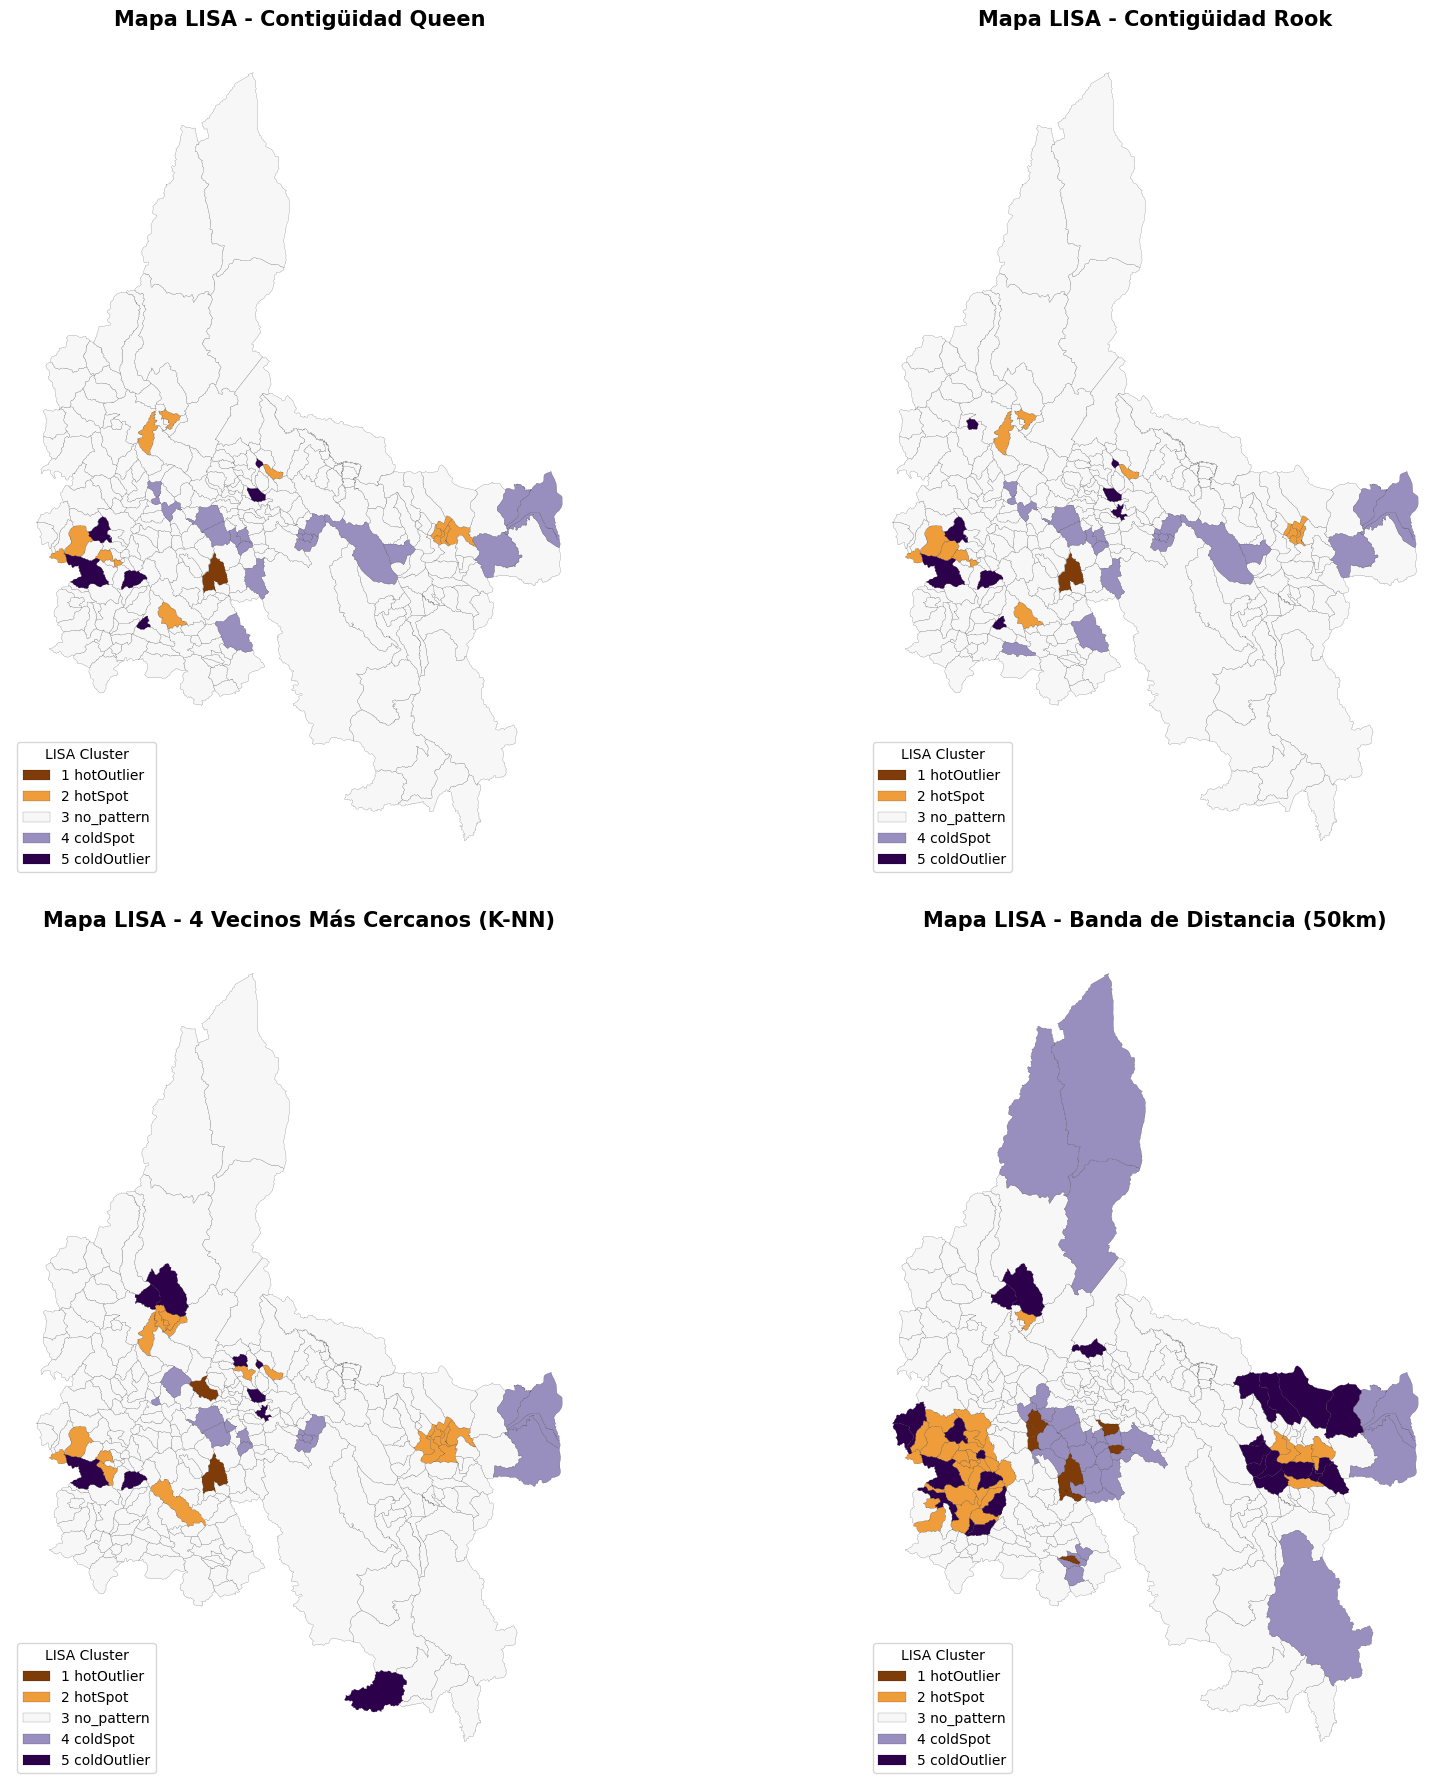

In [ ]:
# Lienzo con 4 cuadrantes
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
myColMap = plt.get_cmap('PuOr', 5)

# Array organizativo de los mapas
mapas_config = [
    ('LISA_Queen', 'Mapa LISA - Contigüidad Queen', axes[0, 0]),
    ('LISA_Rook', 'Mapa LISA - Contigüidad Rook', axes[0, 1]),
    ('LISA_KNN', 'Mapa LISA - 4 Vecinos Más Cercanos (K-NN)', axes[1, 0]),
    ('LISA_Dist', 'Mapa LISA - Banda de Distancia (50km)', axes[1, 1])
]

# Renderizado iterativo de las 4 figuras
for columna, titulo, ax in mapas_config:
    mi_data.plot(column=columna, categorical=True, cmap=myColMap,
                 linewidth=0.1, edgecolor='k', legend=True,
                 legend_kwds={'loc': 'lower left', 'title': 'LISA Cluster'}, ax=ax)
    ax.set_title(titulo, fontsize=15, fontweight='bold')
    ax.set_axis_off()

plt.tight_layout()
plt.show()